In [1]:
# Figure 4: Global climate risk exposure
# Nathan Erickson
# May 13th, 2026

In [1]:
# Import modules
import os
import string
import math
import numpy as np

import pandas as pd
import geopandas

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import cartopy
import seaborn as sns

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

from matplotlib.colors import Normalize,LogNorm,SymLogNorm,FuncNorm,PowerNorm,CenteredNorm
from matplotlib.lines import Line2D

In [2]:
# Set directory structure
base_dir = '' # Fill your directory here
data_dir = os.path.join(base_dir,'Data')
img_dir = os.path.join(base_dir,'FiguresForPaper')

In [3]:
# Load data
os.chdir(data_dir)
gdp_data = pd.read_csv('GDP_Per_Capita.csv')

In [4]:
# Country counts data
country_counts = {
    'Portugal':1,'South Korea':14,'Antarctica':12,
    'China':214,'India':15,'Russia':1,'France':12,
    'Germany':20,'Taiwan':3,'Switzerland':10,'Japan':10,
    'United Kingdom':11,'Netherlands':1,'Canada':7,'Brazil':13,
    'Italy':5,'Finland':2,'Spain':9,'Benin':3,
    'Turkey':2,'Indonesia':5,'Australia':17,'Ireland':1,
    'Nigeria':1,'Hungary':1,'Poland':3,'Argentina':2,
    'Kenya':2,'Romania':1,'Kiribati':1,'New Zealand':3,
    'Iran':5,'Ethiopia':1,'Malaysia':3,'Pakistan':3,
    'Vietnam':1,'Grenada':1,'Morocco':1,'Bangladesh':1,
    'Hong Kong S.A.R.':1,'Mexico':1,'Austria':2,'Thailand':1,
    'Norway':1,'Turkmenistan':1,'Saudi Arabia':2,'United States of America':165
}

## Climate risk analysis

In [5]:
# Load climate risk data
climate_risk = pd.read_csv('CHRI_Exposure.csv')
climate_risk[climate_risk['Country'] == 'Republic of Serbia']

,Country,TMAX>42_2000,TMAX>42_2035,HI>39_2000,HI>39_2035,WBT>27_2000,WBT>27_2035,NT>29_2000,NT>29_2035,P>20_2000,P>20_2035,PM2.5>10_2000,PM2.5>10_2035,D_2000,D_2022,F_2000,F_2022,TC_2000,TC_2022,Unnamed: 19
142,Republic of Serbia,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,99.98,46.74,0.29,0.28,0.06,0.06,0.0,0.0,20-30


In [6]:
# Subset GDP and climate risk data to only include matching countries
full_df = pd.merge(gdp_data,climate_risk,left_on='Country Name',right_on='Country')

In [7]:
# Heatmap studies vs. climate risk components
# Load geospatial reference dataframe
resolution = '10m'
category = 'cultural'
name = 'admin_0_countries'
shpfilename = shpreader.natural_earth(resolution, category, name)

# read the shapefile using geopandas
df_shp = geopandas.read_file(shpfilename)

In [8]:
# CHRI dataframe operations
full_df = full_df.rename(columns={'Unnamed: 19':'CHRI'}) # Rename columns

chri = []
for idx,country in full_df.iterrows():
    min_bound = int(full_df.iloc[idx]['CHRI'].split('-')[0])
    max_bound = int(full_df.iloc[idx]['CHRI'].split('-')[1])
    value = np.mean([min_bound,max_bound])
    chri.append(value)
full_df['CHRI-Values'] = chri
full_df

chri_dict = dict(zip(full_df['Country Name'],full_df['CHRI-Values']))

# Normalize the # of publications by the CHRI
full_df['# Studies Normalized'] = full_df['# Studies'] / full_df['CHRI-Values']
#full_df['# Studies Normalized'] += 0.1 # Add 0.1 to ensure compatability with log-transform
per_chri_dict = dict(zip(full_df['Country Name'],full_df['# Studies Normalized']))

# Compute the correlation between # studies and CHRI
cc_chri = np.corrcoef(full_df['# Studies'],full_df['CHRI-Values'])[0][1]

Text(0.5, 1.0, 'B) AI Applications, Normalized by CHRI\n(Darker Colors = Higher Degree of Climate Risk)')

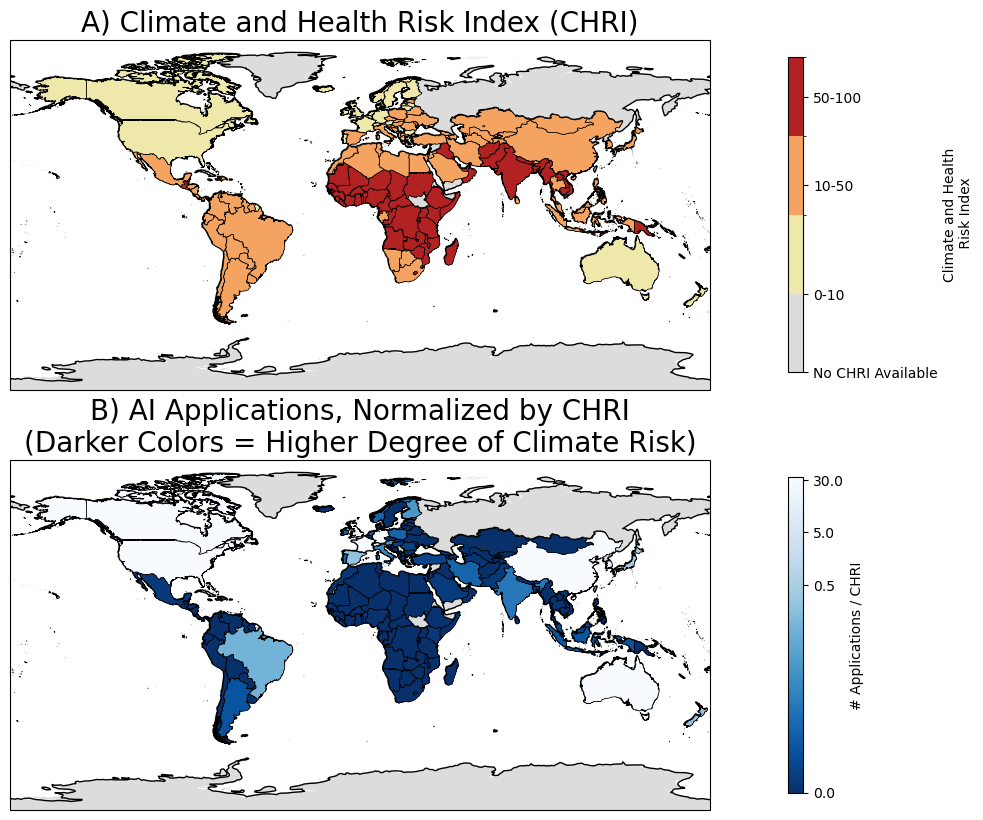

In [13]:
# Plot Figure 4
fig = plt.figure(figsize=(20,10))

# Panel A: Heatmap of global climate risk per CHRI
ax = fig.add_subplot(2,1,1,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

# Create the custom clormap
color_list = ['gainsboro','palegoldenrod','sandybrown','firebrick']
cmap = mpl.colors.ListedColormap(color_list,'endangered')

labels = ['No CHRI Available',
            '0-10','10-50','50-100']
boundaries = np.arange(len(labels) + 1)
tick_positions = np.array([-5,0,25,75])

bounds = [-5,0,10,50,100]
norm = mpl.colors.BoundaryNorm(bounds,ncolors=4)

base_color='gainsboro'
# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,risk_level in chri_dict.items():
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]

    poly_c = cmap(norm(risk_level)) # This line controls the shading of countries; apparently needed to divide by max of normalization to get this right
    
    # Handle France with special white gloves
    if country == 'France': # Need to subset to remove French Guyana
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=base_color, cmap=cmap,
                                   edgecolor='none',zorder=1)

    mapped = ax.add_geometries(poly,crs=ccrs.PlateCarree(),facecolor=poly_c,cmap=cmap,norm=norm,edgecolor='black',linewidth=0.5)
##
    
    centroid = poly.centroid

# Legend for hatching
cb = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),ax=ax,
                  shrink=0.9)
cb.set_label('Climate and Health\n Risk Index') 
cb.ax.set_yticks(tick_positions)
cb.ax.set_yticklabels(labels)

ax.set_title('A) Climate and Health Risk Index (CHRI)',fontsize=20)

# Panel B: Heatmap of # studies, normalized by CHRI
ax = fig.add_subplot(2,1,2,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

cmap=mpl.colormaps.get_cmap('Blues_r')
base_color='gainsboro'

norm = PowerNorm(gamma=0.1,vmin=0,vmax=33) # Power normalization based on # studies / CHRI

# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,risk_level in per_chri_dict.items():
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]

    poly_c = cmap(risk_level) # This line controls the shading of countries; apparently needed to divide by max of normalization to get this right
    
    # Handle France with special white gloves
    if country == 'France': # Need to subset to remove French Guyana
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap, norm=norm,
                                   edgecolor='none', zorder=1)

    else:
        mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap, norm=norm,
                                   edgecolor='black', linewidth=0.5)

# Legend for hatching
cb = fig.colorbar(mapped,ax=ax,shrink=0.9)
cb.set_label('# Applications / CHRI') 
cb.ax.set_yticks([0.0,0.5,5,30])

ax.set_title('B) AI Applications, Normalized by CHRI\n(Darker Colors = Higher Degree of Climate Risk)',fontsize=20)

In [14]:
#os.chdir(img_dir)
os.chdir('../FiguresForPaper')
fig.savefig('Fig4.jpg',bbox_inches='tight',dpi=300)
os.getcwd()

'C:\\Users\\eric0051\\OneDrive - University of Oklahoma\\Documents\\PhD\\Research\\BAMS - Global AI Paper\\FiguresForPaper'

In [ ]:
# Alternative formulation for Figure 4: consider maximum exposure to given climate hazard

period = 'historical'
if period == 'historical':
    tmax_dict = dict(zip(full_df['Country'],full_df['TMAX>42_2000']))
    hi_dict = dict(zip(full_df['Country'],full_df['HI>39_2000']))
    wbt_dict = dict(zip(full_df['Country'],full_df['WBT>27_2000']))
    nt_dict = dict(zip(full_df['Country'],full_df['NT>29_2000']))
    
    precip_dict = dict(zip(full_df['Country'],full_df['P>20_2000']))
    pm_dict = dict(zip(full_df['Country'],full_df['PM2.5>10_2000']))
    
    drought_dict = dict(zip(full_df['Country'],full_df['D_2000']))
    flood_dict = dict(zip(full_df['Country'],full_df['F_2000']))
    tc_dict = dict(zip(full_df['Country'],full_df['TC_2000']))
else:
    tmax_dict = dict(zip(full_df['Country'],full_df['TMAX>42_2035']))
    hi_dict = dict(zip(full_df['Country'],full_df['HI>39_2035']))
    wbt_dict = dict(zip(full_df['Country'],full_df['WBT>27_2035']))
    nt_dict = dict(zip(full_df['Country'],full_df['NT>29_2035']))
    
    precip_dict = dict(zip(full_df['Country'],full_df['P>20_2035']))
    pm_dict = dict(zip(full_df['Country'],full_df['PM2.5>10_2035']))
    
    drought_dict = dict(zip(full_df['Country'],full_df['D_2022']))
    flood_dict = dict(zip(full_df['Country'],full_df['F_2022']))
    tc_dict = dict(zip(full_df['Country'],full_df['TC_2022']))

#full_df = full_df.drop(columns=['Unnamed: 5','Country'])
full_df[full_df['Country Name'] == 'Afghanistan']
# Multiply the drought/flood/TC columns by 100 to get percentages
full_df['D_2000']*=100
full_df['F_2000']*=100
full_df['TC_2000']*=100\

full_df['D_2022']*=100
full_df['F_2022']*=100
full_df['TC_2022']*=100

# Check if any of the columns with 2000 in the name > 10
cols_2000 = [col for col in full_df.columns if '2000' in col]
cols_fut = [col for col in full_df.columns if ('2022' in col) or ('2035' in col)]
#np.count_nonzero((full_df[cols_2000] > 99).any(axis=1))

# Remake this figure with PM 2.5 exposure excluded, since it dominates
#cols_2000 = [col for col in full_df.columns if ('2000' in col) and ('PM' not in col)]
#cols_fut = [col for col in full_df.columns if ('2022' in col) or ('2035' in col) and ('PM' not in col)]
maximum_risk = full_df[cols_fut].max(axis=1)

risk_dict = dict(zip(full_df['Country Name'],maximum_risk))

Text(0.5, 1.0, 'Climate Risk in Understudied Regions')

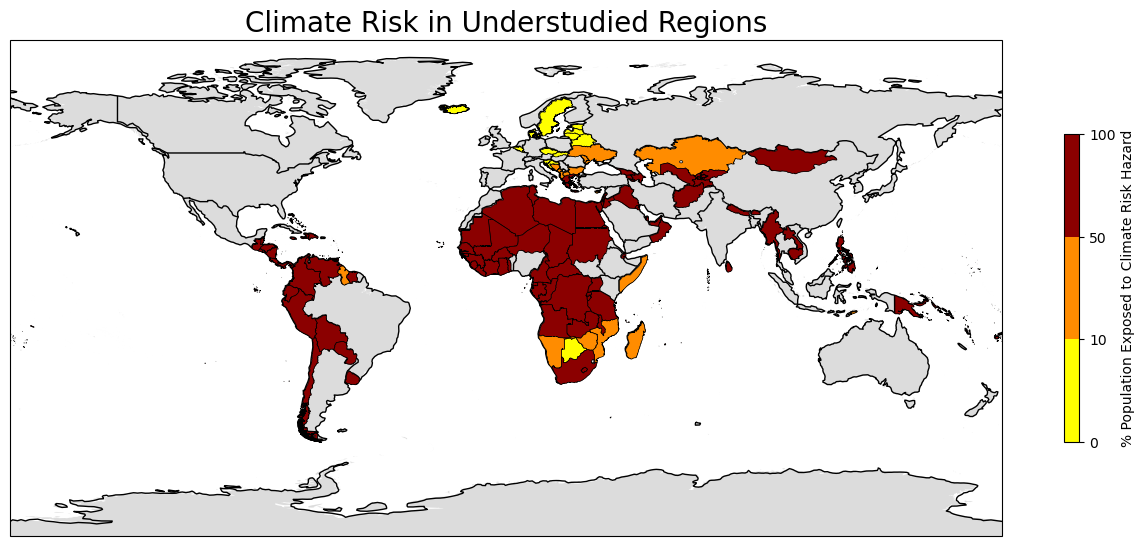

In [17]:
# Map of countries with no studies + climate risk
fig = plt.figure(figsize=(16,8))

# Heatmap of AI studies in meteorology
ax = fig.add_subplot(1,1,1,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

# Createt the custom clormap
color_list = ['yellow','darkorange','darkred']
cmap = mpl.colors.ListedColormap(color_list,'endangered')

bounds = [0,10,50,100]
norm = mpl.colors.BoundaryNorm(bounds,ncolors=3)

base_color='gainsboro'
# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,risk_level in risk_dict.items():
    # read the borders of the country in this loop
    #print('Plotting country ',country)
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]

    poly_c = cmap(risk_level/100) # This line controls the shading of countries; apparently needed to divide by max of normalization to get this right
    
    # Handle France with special white gloves
    if country == 'France': # Need to subset to remove French Guyana
        #print('Subsetting for mainland France')
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=base_color, cmap=cmap,
                                   edgecolor='none',zorder=1)

    # Hatch/color the countries accordingly
    if (full_df[full_df['Country Name'] == country]['# Studies'] > 0).iloc[0]:
        # Don't do anything in this instance
        pass
    else:
        mapped = ax.add_geometries(poly,crs=ccrs.PlateCarree(),facecolor=poly_c,cmap=cmap,edgecolor='black',linewidth=0.5)
    
    centroid = poly.centroid

cb = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap,norm=norm),ax=ax,
                  shrink=0.5)
cb.set_label('% Population Exposed to Climate Risk Hazard') 
ax.set_title('Climate Risk in Understudied Regions',fontsize=20)